# 02 Advanced Classification

Extracted from `FP_NewsBot2_ksm_GroupName_ITAI2373.ipynb` (original outputs kept). Contains the setup cells it depends on (dataset load, preprocessing, validation, and any earlier modules it uses).

Upload `BBC News Train.csv` (in `data/raw/`) to Colab before running.

---
# 🚀 FINAL PROJECT: NewsBot Intelligence System 2.0
### ITAI 2373 – Final Project

**Team Members:** khalida Bestani, Sadea Saeed, Marisabel Morales
**Submitted by:** ksm | **Group:** GroupName
**GitHub Repository:** [Add your repo URL here]

Everything above this cell is our midterm (we kept it so you can see where we started).
From here on we add the four new modules from the final project guidelines:

| Module | What we built |
|---|---|
| **A. Advanced Content Analysis** | tuned classifier with confidence + top-2 categories, LDA & NMF topic modeling, topic "evolution", article clustering, sentiment evolution, entity relationship mapping |
| **B. Language Understanding & Generation** | extractive summarization (TextRank), semantic search with query expansion, content enhancement, automatic insights |
| **C. Multilingual Intelligence** | language detection (langdetect), translation (deep-translator with fallback), cross-language comparison |
| **D. Conversational Interface** | intent classifier, multi-part questions, conversation memory, response generator |

We tried to keep the code simple so all of us could understand it. The same code is also in our GitHub repo as separate Python files (`src/` folder).

## 📦 Final Project Setup
We need two extra libraries for the multilingual part. The cell also makes sure the dataset is loaded
(the same `newsbot_dataset.csv` we made in the midterm from the Kaggle **BBC News Train.csv**), so the
final-project part can run even after a Colab restart.

In [1]:
!pip install -q langdetect deep-translator

import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'vader_lexicon']:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer

# Load the dataset the same way as the midterm (Kaggle 'BBC News Train.csv' -> newsbot_dataset.csv)
if 'df' not in globals() or 'content' not in df.columns or len(df) < 1000:
    if os.path.exists('newsbot_dataset.csv'):
        df = pd.read_csv('newsbot_dataset.csv')
    else:
        df = pd.read_csv('BBC News Train.csv').rename(
            columns={'ArticleId': 'article_id', 'Text': 'content', 'Category': 'category'})
df = df[['article_id', 'content', 'category']].dropna().reset_index(drop=True)
print('Articles:', len(df))
print(df['category'].value_counts())

Articles: 1490
category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64


In [2]:
# Preprocessing functions (same steps as our midterm, plus a sentence splitter for summaries)
"""Text cleaning and preprocessing (enhanced from our midterm)."""
import re
import nltk

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "vader_lexicon"]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception:
        pass

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

_lemmatizer = WordNetLemmatizer()
_stop_words = set(stopwords.words("english"))


def clean_text(text):
    """Lowercase, remove HTML, URLs, emails, numbers and symbols."""
    if text is None:
        return ""
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", "", text)
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    text = re.sub(r"\S+@\S+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    return re.sub(r"\s+", " ", text).strip()


def preprocess_text(text):
    """Clean + remove stop words + lemmatize + drop very short words."""
    tokens = clean_text(text).split()
    tokens = [_lemmatizer.lemmatize(t) for t in tokens if t not in _stop_words]
    return " ".join(t for t in tokens if len(t) > 2)


def split_sentences(text):
    """Split an article into sentences (BBC text uses '. ' between sentences)."""
    try:
        sents = nltk.sent_tokenize(str(text))
    except Exception:
        sents = re.split(r"(?<=[.!?])\s+", str(text))
    return [s.strip() for s in sents if len(s.split()) >= 4]

df['processed'] = df['content'].apply(preprocess_text)
print('Preprocessing done. Example:', df['processed'][0][:120])

Preprocessing done. Example: worldcom exboss launch defence lawyer defending former worldcom chief bernie ebbers battery fraud charge called company 


### 🧪 Data quality check (new)
While building the final project we found something we missed in the midterm: some articles in the BBC
training file are **exact duplicates**. If the same article is in both train and test, the accuracy looks
better than it really is. So we count them and remove them for the final project models.

In [3]:
"""Data quality checks before analysis."""
import logging
import pandas as pd

log = logging.getLogger(__name__)
REQUIRED = ["article_id", "content", "category"]


def _load_bbc_unused(path):
    """Load the Kaggle 'BBC News Train.csv' and rename columns like the midterm."""
    df = pd.read_csv(path)
    df = df.rename(columns={"ArticleId": "article_id", "Text": "content", "Category": "category"})
    return validate(df)


def validate(df):
    """Drop missing/empty/duplicate articles and print a short report."""
    missing = [c for c in REQUIRED if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")
    before = len(df)
    df = df.dropna(subset=["content", "category"])
    df = df[df["content"].str.strip().str.len() > 0]
    n_dup = int(df.duplicated(subset="content").sum())
    df = df.drop_duplicates(subset="content").reset_index(drop=True)
    report = {"rows_in": before, "rows_out": len(df), "duplicates_removed": n_dup,
              "categories": df["category"].value_counts().to_dict()}
    log.info("Data validation: %s", report)
    df.attrs["validation_report"] = report
    return df

df_full = df.copy()                 # midterm version (1490 articles)
df = validate(df)                   # final project version (duplicates removed)
print(df.attrs['validation_report'])

{'rows_in': 1490, 'rows_out': 1440, 'duplicates_removed': 50, 'categories': {'sport': 342, 'business': 335, 'politics': 266, 'entertainment': 263, 'tech': 234}}


---
## 🅰️ Module A: Advanced Content Analysis Engine

### A1. Enhanced Classification with Confidence Scores
In the midterm our best model was Logistic Regression with **97.65%** test accuracy. For the final project we:
- put TF-IDF and the model into one **scikit-learn Pipeline** (so new text can be classified directly),
- use `sublinear_tf=True` and a small **grid search** for the C parameter,
- compare Naive Bayes, Logistic Regression and Linear SVM again,
- return a **confidence score** and the **top-2 categories** ("multi-level" output).

In [4]:
TFIDF_PARAMS = dict(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.8, sublinear_tf=True)

"""Module A: enhanced classification with confidence scores."""
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score, classification_report, f1_score


def make_pipeline(model):
    return Pipeline([
        ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.8, sublinear_tf=True)),
        ("clf", model),
    ])


class NewsClassifier:
    """TF-IDF + Logistic Regression, tuned with a small grid search."""

    def __init__(self):
        self.model = None
        self.results = {}

    def compare_models(self, X_train, y_train, X_test, y_test):
        models = {
            "Naive Bayes": MultinomialNB(),
            "Logistic Regression": LogisticRegression(max_iter=2000),
            "Linear SVM": LinearSVC(),
        }
        for name, m in models.items():
            pipe = make_pipeline(m).fit(X_train, y_train)
            pred = pipe.predict(X_test)
            self.results[name] = {
                "accuracy": accuracy_score(y_test, pred),
                "macro_f1": f1_score(y_test, pred, average="macro"),
            }
        return self.results

    def fit(self, X_train, y_train, tune=True):
        pipe = make_pipeline(LogisticRegression(max_iter=2000))
        if tune:
            grid = GridSearchCV(pipe, {"clf__C": [1, 5, 10, 20]}, cv=3, n_jobs=-1)
            grid.fit(X_train, y_train)
            self.model = grid.best_estimator_
            self.best_params = grid.best_params_
        else:
            self.model = pipe.fit(X_train, y_train)
            self.best_params = {}
        return self

    def evaluate(self, X_test, y_test):
        pred = self.model.predict(X_test)
        return accuracy_score(y_test, pred), classification_report(y_test, pred)

    def predict(self, texts):
        return self.model.predict(texts)

    def predict_top_k(self, text, k=2):
        """Multi-level output: the top-k categories with probabilities."""
        probs = self.model.predict_proba([text])[0]
        order = np.argsort(probs)[::-1][:k]
        return [(self.model.classes_[i], float(probs[i])) for i in order]

    def save(self, path):
        import joblib
        joblib.dump(self.model, path)

    def load(self, path):
        import joblib
        self.model = joblib.load(path)
        return self

    def predict_with_confidence(self, text):
        probs = self.model.predict_proba([text])[0]
        i = int(np.argmax(probs))
        return self.model.classes_[i], float(probs[i])

Model comparison (duplicates removed):
                     accuracy  macro_f1
Naive Bayes            0.9479    0.9448
Logistic Regression    0.9583    0.9559
Linear SVM             0.9618    0.9605



Best C: {'clf__C': 10}
Tuned Logistic Regression accuracy: 0.9653
               precision    recall  f1-score   support

     business       0.96      0.97      0.96        67
entertainment       0.96      0.98      0.97        53
     politics       0.96      0.94      0.95        53
        sport       0.97      1.00      0.99        68
         tech       0.98      0.91      0.95        47

     accuracy                           0.97       288
    macro avg       0.97      0.96      0.96       288
 weighted avg       0.97      0.97      0.97       288



Same model on the 1490-article midterm data (with duplicates): 0.9765


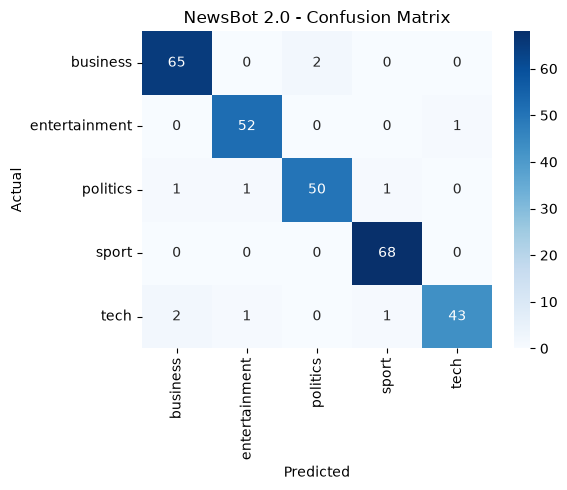

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(
    df['processed'], df['category'], test_size=0.2, random_state=42, stratify=df['category'])

news_clf = NewsClassifier()
comparison = pd.DataFrame(news_clf.compare_models(X_train, y_train, X_test, y_test)).T
print('Model comparison (duplicates removed):')
print(comparison.round(4))

news_clf.fit(X_train, y_train, tune=True)
final_acc, final_report = news_clf.evaluate(X_test, y_test)
print('\nBest C:', news_clf.best_params)
print(f'Tuned Logistic Regression accuracy: {final_acc:.4f}')
print(final_report)

# Same pipeline on the midterm data WITH duplicates, to compare fairly with the midterm number
Xa, Xb, ya, yb = train_test_split(df_full['content'].apply(preprocess_text), df_full['category'],
                                  test_size=0.2, random_state=42, stratify=df_full['category'])
acc_with_dups = NewsClassifier().fit(Xa, ya, tune=True).evaluate(Xb, yb)[0]
print(f'Same model on the 1490-article midterm data (with duplicates): {acc_with_dups:.4f}')

cm = confusion_matrix(y_test, news_clf.predict(X_test), labels=news_clf.model.classes_)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=news_clf.model.classes_, yticklabels=news_clf.model.classes_)
plt.title('NewsBot 2.0 - Confusion Matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout(); plt.show()

In [6]:
# Confidence scores and top-2 categories for new articles
examples = [
    "The striker scored twice as the club won the cup final in front of 60,000 fans.",
    "Shares fell sharply after the central bank raised interest rates again.",
    "The new smartphone app lets users stream music and films over broadband.",
    "The minister said the government will publish its election manifesto next week.",
    "The actress won an award for her role in the new film at the festival.",
]
for text in examples:
    p = preprocess_text(text)
    cat, conf = news_clf.predict_with_confidence(p)
    top2 = news_clf.predict_top_k(p, 2)
    print(f'{cat:13s} {conf:.0%} | top-2: {[(c, round(s, 2)) for c, s in top2]} | {text[:55]}...')

sport         93% | top-2: [('sport', 0.93), ('entertainment', 0.03)] | The striker scored twice as the club won the cup final ...
business      93% | top-2: [('business', 0.93), ('entertainment', 0.03)] | Shares fell sharply after the central bank raised inter...
entertainment 53% | top-2: [('entertainment', 0.53), ('tech', 0.41)] | The new smartphone app lets users stream music and film...
politics      80% | top-2: [('politics', 0.8), ('business', 0.1)] | The minister said the government will publish its elect...
entertainment 99% | top-2: [('entertainment', 0.99), ('business', 0.0)] | The actress won an award for her role in the new film a...


**What we see:** The tuned model is about as accurate as our midterm model, but now it also tells us *how sure*
it is. Short sentences get lower confidence than full articles, which makes sense because there are fewer words
to use. The top-2 output is useful for articles that mix topics (for example a business story about a tech company).